Fase 1: Análise Exploratória (EDA)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/manutencao_preditiva.csv")

print("Linhas e colunas:", df.shape)
print()
print(df.dtypes)

Linhas e colunas: (10000, 14)

udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object


In [3]:
colunas_num = ["temperatura_ar_k", "temperatura_processo_k",
               "velocidade_rotacao_rpm", "torque_nm", "desgaste_ferramenta_min"]

df[colunas_num].describe()

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min
count,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000
mean,300.002158,310.000895,1539.245263,39.974168,107.951000
std,2.001689,1.486432,180.273589,9.995453,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.100000,53.000000
50%,300.100000,310.100000,1504.000000,40.100000,108.000000
75%,301.500000,311.100000,1613.000000,46.700000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


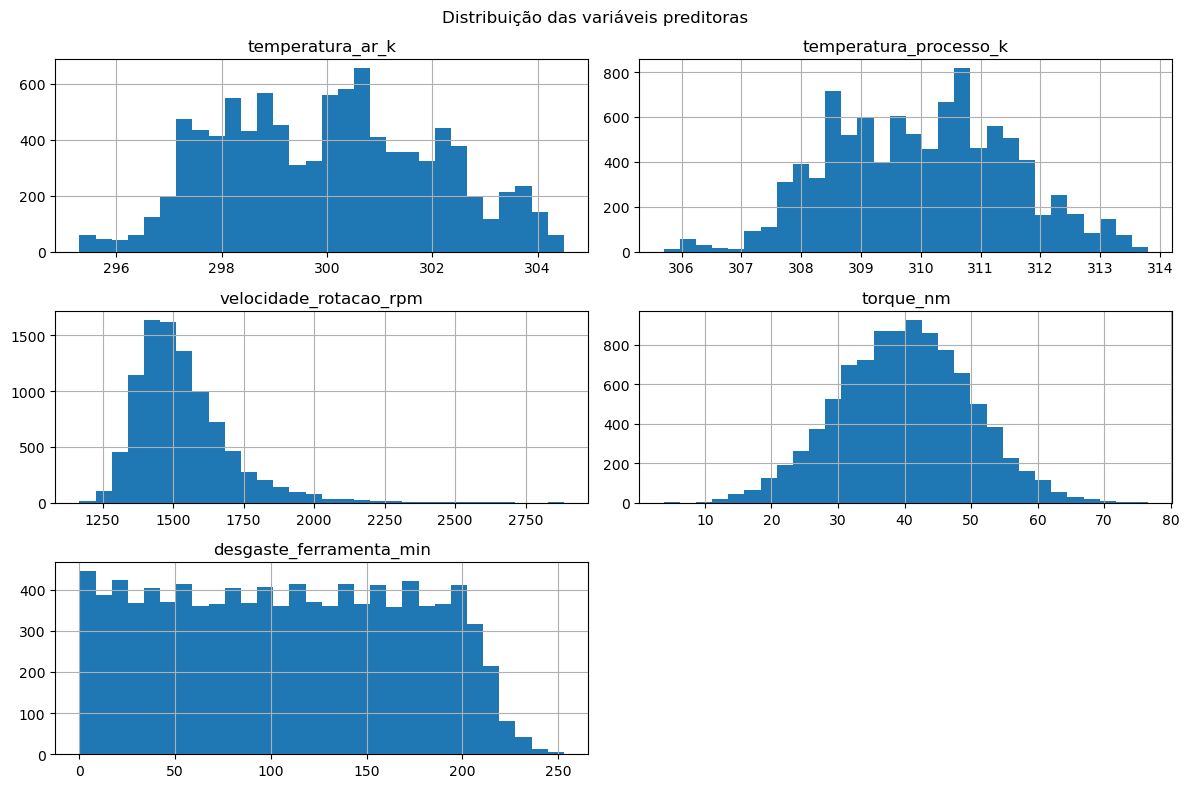

In [4]:
df[colunas_num].hist(bins=30, figsize=(12, 8))
plt.suptitle("Distribuição das variáveis preditoras")
plt.tight_layout()
plt.show()

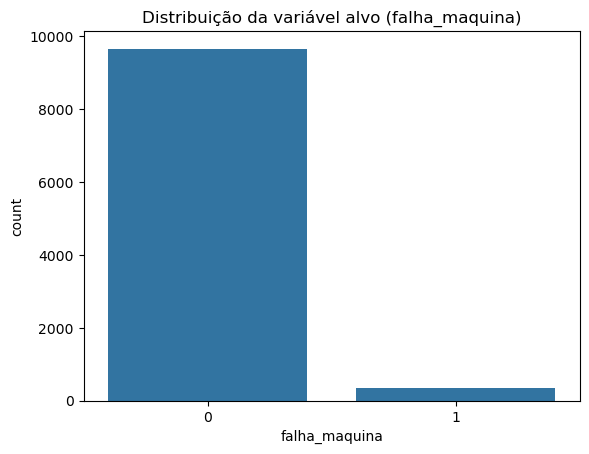

falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


In [5]:
ax = sns.countplot(x="falha_maquina", data=df)
ax.set_title("Distribuição da variável alvo (falha_maquina)")
plt.show()

print(df["falha_maquina"].value_counts(normalize=True).round(4) * 100)

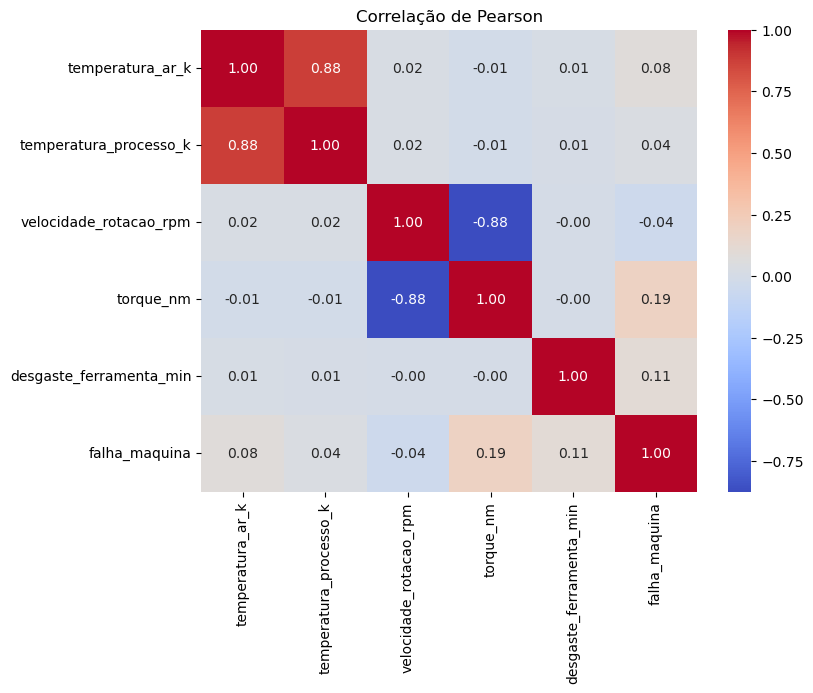

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[colunas_num + ["falha_maquina"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlação de Pearson")
plt.show()

Após análise verifiquei que: Alvo: 3,39% de falhas, então a base está desbalanceada. A acurácia sozinha engana, porque um modelo que sempre diz “sem falha” acerta cerca de 96,6%. Com isso, é preciso balancear o treino.
Com relação as Distribuições, a rotação é assimétrica à direita, com cauda até ~2.886 rpm. O torque é aproximadamente normal. O desgaste é quase uniforme e cai depois de ~200 min. As temperaturas são irregulares, com isso, cabe usar mediana na rotação e checar outliers.
Já na análise das Correlações com as falhas, constatou-se que: as correlações são fracas (torque 0,19, desgaste 0,11). Entre variáveis, os dois pares fortes acima. Consequência: nenhum modelo será perfeito, e o KNN pode sofrer com as variáveis redundantes.

Fase 2: Limpeza e Tratamento de Dados (Data Prep)

Fase 3: Feature Engineering

Fase 4: Divisão e Balanceamento dos Dados

Fase 5: Escalonamento de Variáveis (StandardScaler)

Fase 6: Ajuste de Parâmetros e Combate ao Overfitting

Fase 7: Avaliação da Acurácia e Veredito Final